# Textile Export Supply Chain Analysis
### Delivery performance · Supplier scorecard · Inventory targets · Demand forecast

**Context.** A vertically integrated home-textile exporter (towels, bed linen, yarn) buys cotton and other materials, makes products, and ships them to retailers in many countries. This notebook answers four practical questions:

1. Are export orders delivered **on time and in full (OTIF)**, and what causes the misses?
2. Which **raw-material suppliers** are reliable and good value?
3. Is **inventory** at the right level (stock-outs vs excess stock)?
4. How much will customers order over the **next 13 weeks**?

**Tools:** Python with NumPy, pandas, scikit-learn (linear regression) and matplotlib.

> **Data note:** the data is *synthetic* (made by `generate_data.py`, fixed seed) because real company data is confidential. Numbers are illustrative; the methods work the same on real data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.options.display.float_format = lambda x: f"{x:,.0f}" if float(x).is_integer() else f"{x:,.2f}"
DATA = "../data/"

## 1. Load and prepare the data

In [2]:
orders    = pd.read_csv(DATA + "sales_orders.csv", parse_dates=["order_date", "promised_date", "delivery_date"])
po        = pd.read_csv(DATA + "purchase_orders.csv", parse_dates=["po_date", "receipt_date"])
suppliers = pd.read_csv(DATA + "suppliers.csv")
skus      = pd.read_csv(DATA + "sku_master.csv")
inventory = pd.read_csv(DATA + "inventory_monthly.csv")

for name, df in dict(sales_orders=orders, purchase_orders=po, suppliers=suppliers,
                     sku_master=skus, inventory_monthly=inventory).items():
    print(f"{name:<18}{df.shape[0]:>7,} rows x {df.shape[1]:>2} cols")

print("\nDuplicate order IDs:", orders.order_id.duplicated().sum())
print("Orders still in transit (no delivery date):", orders.delivery_date.isna().sum())
print("Purchase orders with no defect rate (lot not inspected):", po.defect_rate_pct.isna().sum())
orders.head()

sales_orders        7,063 rows x 12 cols
purchase_orders     1,244 rows x 11 cols
suppliers              12 rows x  4 cols
sku_master              5 rows x  9 cols
inventory_monthly     120 rows x  7 cols

Duplicate order IDs: 0
Orders still in transit (no delivery date): 238
Purchase orders with no defect rate (lot not inspected): 13


,order_id,order_date,customer_id,region,sku,quantity,unit_price_usd,shipping_mode,promised_date,delivery_date,delivered_qty,order_status
0,SO-000001,2023-01-01,CUST-006,Australia,BED-01,6600,9.24,Sea,2023-02-04,2023-02-01,"6,600",Delivered
1,SO-000002,2023-01-01,CUST-026,USA,TWL-02,23300,1.58,Sea,2023-02-08,2023-02-05,"23,300",Delivered
2,SO-000003,2023-01-01,CUST-038,Europe,TWL-01,8800,4.33,Air,2023-01-09,2023-01-07,"7,735",Delivered
3,SO-000004,2023-01-01,CUST-017,Europe,TWL-01,5400,4.55,Sea,2023-02-02,2023-01-30,"5,400",Delivered
4,SO-000005,2023-01-02,CUST-004,UK,BED-01,7700,9.78,Sea,2023-02-02,2023-01-30,"7,700",Delivered


In [3]:
# --- sales orders ---
orders["revenue"] = orders.quantity * orders.unit_price_usd
orders["month"]   = orders.order_date.dt.to_period("M")
orders["year"]    = orders.order_date.dt.year

# delivery KPIs use only orders that have been delivered
delivered = orders[orders.order_status == "Delivered"].copy()
delivered["delay_days"] = (delivered.delivery_date - delivered.promised_date).dt.days
delivered["on_time"] = delivered.delay_days <= 0                    # arrived on/before promised date
delivered["in_full"] = delivered.delivered_qty >= delivered.quantity  # full quantity delivered
delivered["otif"]    = delivered.on_time & delivered.in_full          # both

# --- purchase orders ---
po = po.merge(suppliers[["supplier_id", "supplier_name", "location"]], on="supplier_id")
po["delay_days"] = po.actual_lead_days - po.promised_lead_days
po["on_time"]    = po.delay_days <= 0
po["spend"]      = po.quantity_kg * po.price_per_kg_inr
po["month"]      = po.po_date.dt.to_period("M")
print("Delivered orders:", len(delivered), "| purchase orders:", len(po))

Delivered orders: 6825 | purchase orders: 1244


## 2. Sales overview

Revenue 2023: $135.7M | 2024: $155.6M | growth +14.7%
Aug-Oct = 30.9% of annual revenue (25% if demand were flat)
USA + Europe = 58.5% of revenue


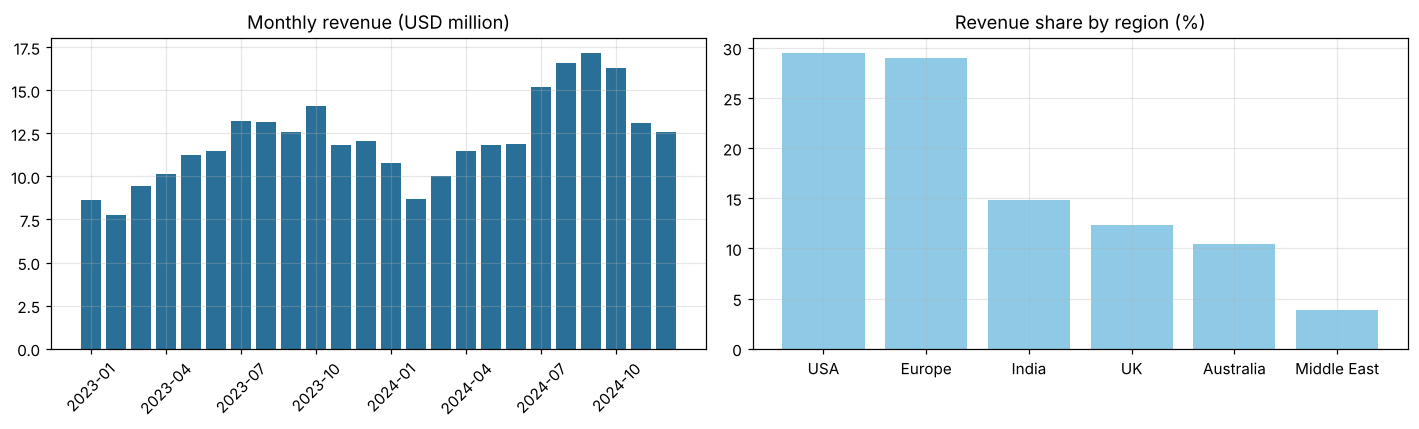

In [4]:
monthly = orders.groupby("month").revenue.sum() / 1e6
region  = orders.groupby("region").revenue.sum().sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(monthly.index.astype(str), monthly.values, color="#2a6f97")
ax[0].set_xticks(range(0, len(monthly), 3))
ax[0].set_xticklabels(monthly.index.astype(str)[::3], rotation=45)
ax[0].set_title("Monthly revenue (USD million)")
ax[1].bar(region.index, region.values / region.sum() * 100, color="#8ecae6")
ax[1].set_title("Revenue share by region (%)")
plt.tight_layout()

yearly = orders.groupby("year").revenue.sum()
by_month_no = orders.groupby(orders.order_date.dt.month).revenue.sum()
print(f"Revenue 2023: ${yearly[2023]/1e6:,.1f}M | 2024: ${yearly[2024]/1e6:,.1f}M | growth {yearly[2024]/yearly[2023]-1:+.1%}")
print(f"Aug-Oct = {by_month_no.loc[[8, 9, 10]].sum() / by_month_no.sum():.1%} of annual revenue (25% if demand were flat)")
print(f"USA + Europe = {(region['USA'] + region['Europe']) / region.sum():.1%} of revenue")

**Takeaways**
- Revenue grew **14.7%** (US$135.7M to US$155.6M). Aug-Oct brings **30.9%** of annual revenue, so the busy season needs extra planning.
- The USA and Europe together make up **58.5%** of revenue.

## 3. Delivery performance (OTIF)
An order is **OTIF** only if it arrives on or before the promised date **and** the full quantity is delivered.

OVERALL: on-time 75.4% | in-full 91.7% | OTIF 69.3%

BY REGION
             orders  on_time_%  in_full_%  OTIF_%
region                                           
Australia       726      67.40      92.60   62.40
USA            1966      71.90      91.30   65.50
Middle East     271      73.10      92.60   67.20
India          1197      74.90      91.90   68.90
Europe         1839      79.40      91.60      73
UK              826      83.40      91.80   77.10

BY SHIPPING MODE
               orders  on_time_%  in_full_%  OTIF_%
shipping_mode                                      
Air               580      85.70      90.90   77.10
Road             1197      74.90      91.90   68.90
Sea              5048      74.30      91.80   68.50

SEA FREIGHT: PEAK vs OFF-PEAK
                orders  on_time_%  in_full_%  OTIF_%
season                                              
Off-peak          3389      82.30      93.40      77
Peak (Aug-Oct)    1659      58.10      88.50   51.10

Late orders: 24

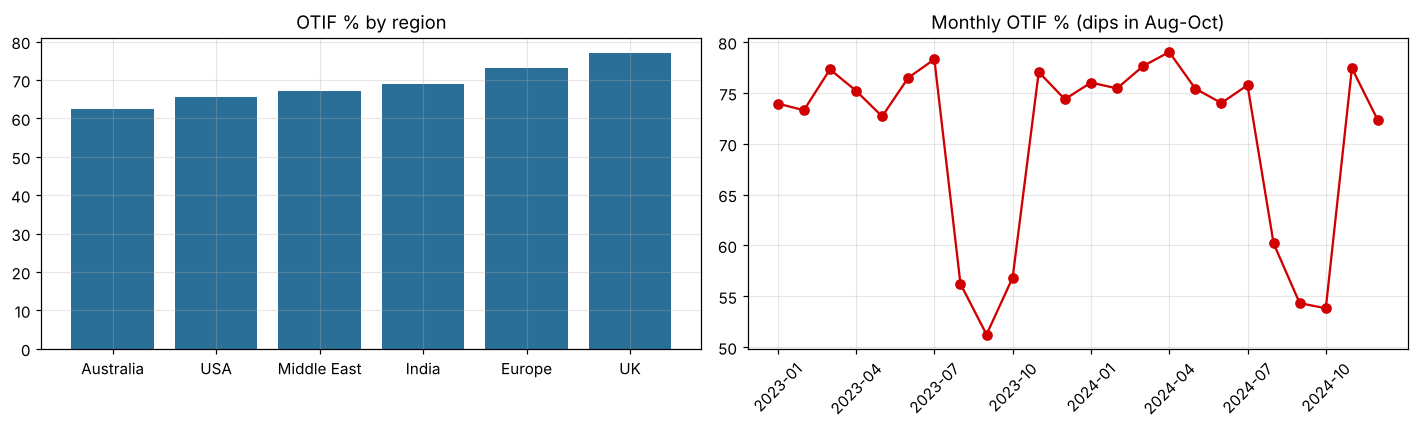

In [5]:
def otif_table(df, by):
    g = df.groupby(by)
    return pd.DataFrame({"orders": g.size(),
                         "on_time_%": g.on_time.mean() * 100,
                         "in_full_%": g.in_full.mean() * 100,
                         "OTIF_%": g.otif.mean() * 100}).round(1)

print(f"OVERALL: on-time {delivered.on_time.mean():.1%} | in-full {delivered.in_full.mean():.1%} | OTIF {delivered.otif.mean():.1%}")
by_region = otif_table(delivered, "region").sort_values("OTIF_%")
print("\nBY REGION"); print(by_region.to_string())
print("\nBY SHIPPING MODE"); print(otif_table(delivered, "shipping_mode").to_string())

# sea freight: peak season (Aug-Oct) vs rest of the year
sea = delivered[delivered.shipping_mode == "Sea"].copy()
sea["season"] = np.where(sea.order_date.dt.month.isin([8, 9, 10]), "Peak (Aug-Oct)", "Off-peak")
print("\nSEA FREIGHT: PEAK vs OFF-PEAK"); print(otif_table(sea, "season").to_string())

late = delivered[~delivered.on_time]
print(f"\nLate orders: {len(late)/len(delivered):.1%} of orders = ${late.revenue.sum()/1e6:,.1f}M of revenue")

monthly_otif = delivered.groupby("month").otif.mean() * 100
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(by_region.index, by_region["OTIF_%"], color="#2a6f97"); ax[0].set_title("OTIF % by region")
ax[1].plot(monthly_otif.index.astype(str), monthly_otif.values, marker="o", color="#d00000")
ax[1].set_xticks(range(0, len(monthly_otif), 3)); ax[1].set_xticklabels(monthly_otif.index.astype(str)[::3], rotation=45)
ax[1].set_title("Monthly OTIF % (dips in Aug-Oct)")
plt.tight_layout()

**Takeaways**
- Only **69.3% of orders are OTIF** (75.4% on time, 91.7% in full).
- **Peak season is the main problem:** sea-freight OTIF falls from **77.0% to 51.1%** in Aug-Oct.
- Australia (62.4%) and the USA (65.5%) are the weakest regions, which are the longest sea routes.
- **24.6%** of delivered orders (US$68.1M of revenue) arrived late.
- **Action:** start production earlier for the Aug-Oct peak, book freight in advance and promise longer lead times on long routes.

## 4. Supplier scorecard
Each supplier is scored out of 100 using three measures: **on-time delivery (50%)**, **quality / defect rate (30%)** and **price vs the market average for that material in the same month (20%)**. The weights are a choice and easy to change.

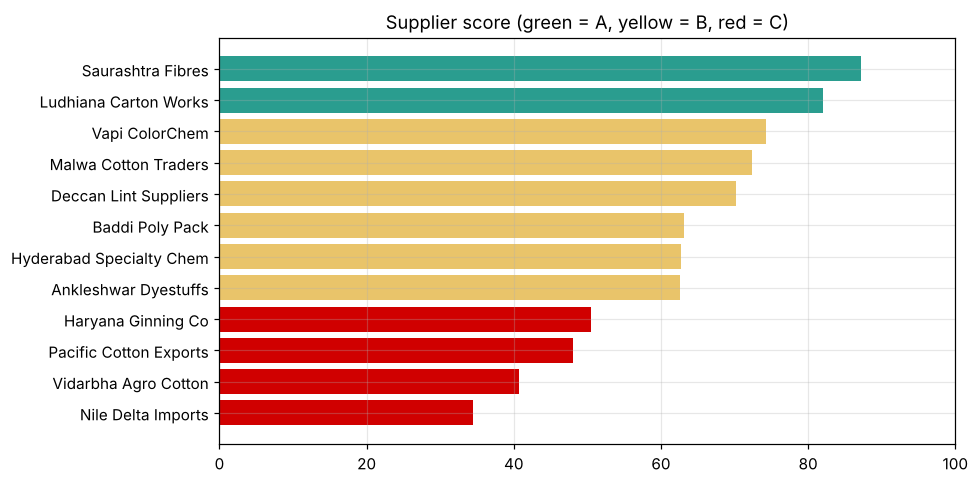

,supplier_name,material,pos,spend_inr_m,on_time_%,avg_delay_days,defect_pct,price_index,score,tier
0,Saurashtra Fibres,Raw Cotton,113,808.20,94.70,-0.90,1,95.90,87.20,A - Preferred
1,Ludhiana Carton Works,Packaging,70,39.50,87.10,-0.90,0.70,102.10,82,A - Preferred
2,Vapi ColorChem,Dyes & Chemicals,104,171,75,-0.40,0.90,100.90,74.30,B - Approved
3,Malwa Cotton Traders,Raw Cotton,113,846.50,71.70,-0.30,1.40,93.10,72.30,B - Approved
4,Deccan Lint Suppliers,Raw Cotton,107,750.40,65.40,0.10,1.30,92.60,70.20,B - Approved
5,Baddi Poly Pack,Packaging,90,42.80,52.20,0.50,1.10,98.40,63.10,B - Approved
6,Hyderabad Specialty Chem,Dyes & Chemicals,85,160.90,61.20,0.20,1.10,105.50,62.70,B - Approved
7,Ankleshwar Dyestuffs,Dyes & Chemicals,124,189.20,54.80,0.70,1.50,95.50,62.60,B - Approved
8,Haryana Ginning Co,Raw Cotton,116,854.20,37.10,1.40,1.80,90.90,50.50,C - Review
9,Pacific Cotton Exports,Raw Cotton,103,909.60,39.80,2.60,0.90,115,48.10,C - Review


In [6]:
po["price_index"] = po.price_per_kg_inr / po.groupby(["material", "month"]).price_per_kg_inr.transform("mean") * 100

sc = po.groupby(["supplier_name", "material"]).agg(
        pos=("po_id", "count"), spend=("spend", "sum"), on_time=("on_time", "mean"),
        avg_delay_days=("delay_days", "mean"), defect_pct=("defect_rate_pct", "mean"),
        price_index=("price_index", "mean")).reset_index()
sc["spend_inr_m"] = sc.spend / 1e6
sc["on_time_%"]   = sc.on_time * 100

on_time_score = sc.on_time                                   # already 0-1
quality_score = (1 - sc.defect_pct / 3).clip(0, 1)           # 0% defects = 1, 3%+ = 0
price_score   = (1 - (sc.price_index - 95) / 30).clip(0, 1)  # index 95 = 1, 125+ = 0
sc["score"] = 100 * (0.5 * on_time_score + 0.3 * quality_score + 0.2 * price_score)
sc["tier"]  = pd.cut(sc.score, [0, 60, 75, 100], labels=["C - Review", "B - Approved", "A - Preferred"])
sc = sc.sort_values("score", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = sc.tier.map({"A - Preferred": "#2a9d8f", "B - Approved": "#e9c46a", "C - Review": "#d00000"}).astype(str)
ax.barh(sc.supplier_name[::-1], sc.score[::-1], color=colors[::-1].values)
ax.set_xlim(0, 100); ax.set_title("Supplier score (green = A, yellow = B, red = C)")
plt.tight_layout()

sc[["supplier_name", "material", "pos", "spend_inr_m", "on_time_%", "avg_delay_days", "defect_pct", "price_index", "score", "tier"]].round(1)

In [7]:
# raw cotton: domestic vs imported suppliers
cot = po[po.material == "Raw Cotton"].copy()
cot["source"] = np.where(cot.location.str.contains("Import"), "Imported", "Domestic")
g = cot.groupby("source")
cotton = pd.DataFrame({"price_inr_per_kg": g.spend.sum() / g.quantity_kg.sum(),
                       "avg_lead_days": g.actual_lead_days.mean(),
                       "on_time_%": g.on_time.mean() * 100,
                       "share_of_kg_%": g.quantity_kg.sum() / cot.quantity_kg.sum() * 100}).round(1)
print(cotton.to_string())

c_spend = sc[sc.material == "Raw Cotton"]
tier_c = c_spend[c_spend.tier == "C - Review"]
print(f"\nTier-C cotton suppliers: {', '.join(tier_c.supplier_name)}")
print(f"They hold {tier_c.spend.sum() / c_spend.spend.sum():.1%} of cotton spend")

          price_inr_per_kg  avg_lead_days  on_time_%  share_of_kg_%
source                                                             
Domestic            159.70           8.30      60.10          72.60
Imported            208.80          41.80      30.80          27.40

Tier-C cotton suppliers: Haryana Ginning Co, Pacific Cotton Exports, Vidarbha Agro Cotton, Nile Delta Imports
They hold 59.6% of cotton spend


**Takeaways**
- **Best suppliers:** Saurashtra Fibres (87) and Ludhiana Carton Works (82), with on-time deliveries of 94.7% and 87.1%.
- **Weakest suppliers:** four cotton suppliers (Haryana Ginning, Pacific Cotton Exports, Vidarbha Agro, Nile Delta Imports) score below 60 and hold **59.6% of cotton spend**.
- **Nile Delta Imports** is the largest supplier by spend, but only 22.5% of its deliveries are on time and its prices are 24% above the material average.
- **Imported cotton** costs **Rs 209/kg vs Rs 160/kg** domestic (+31%) and takes **42 days vs 8**.
- **Action:** move volume from the weakest domestic suppliers to Saurashtra and Malwa, and plan imported cotton orders much earlier.

## 5. Inventory targets: EOQ and safety stock
For each product (using 2024 demand):

* **EOQ** (economic batch size) = sqrt(2 x D x S / H) where D = annual demand, S = set-up cost per batch, H = yearly holding cost per unit (unit cost x holding %).
* **Safety stock** = Z x (std dev of daily demand) x sqrt(production lead time), with Z = 1.65 for a 95% service level.
* **Target average stock** = safety stock + EOQ / 2.

We then compare the target with the actual average stock and count stock-outs.

Total estimated lost revenue from stock-outs in 2024: $4.35M (at list price)


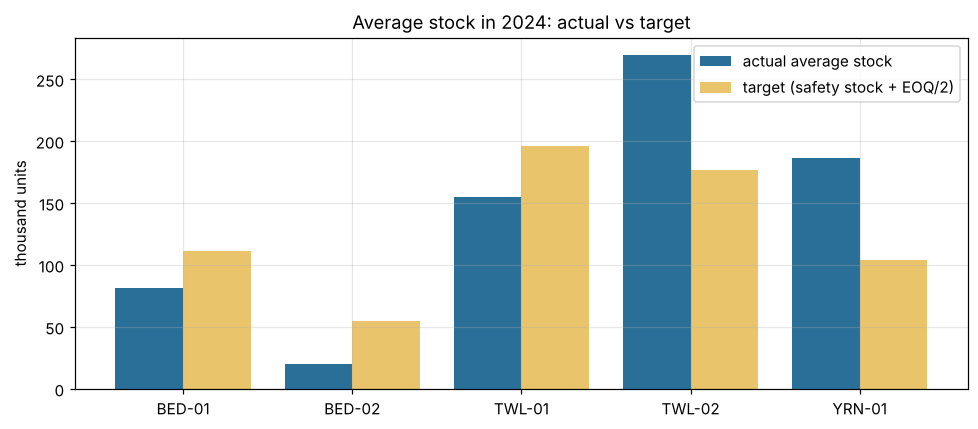

,annual_demand,EOQ,safety_stock,target_avg_stock,avg_stock,stockout_months,lost_sales_%,lost_revenue_usd
sku,,,,,,,,
BED-01,"5,335,800","34,823.60","94,113.30","111,525.10","81,528.10",2,3.90,"1,986,193.50"
BED-02,"1,841,800","18,355.20","45,653.30","54,830.90","19,988.80",5,3.40,"747,093.40"
TWL-01,"11,908,300","66,929.90","162,628.20","196,093.20","154,681.80",3,3.20,"1,618,310.40"
TWL-02,"7,694,400","79,743.40","136,619","176,490.70","269,849.80",0,0,0
YRN-01,"5,582,400","69,748.40","68,938.40","103,812.60","186,426.80",0,0,0


In [8]:
Z = 1.65                                   # 95% service level
p = skus.set_index("sku")
days = pd.date_range("2024-01-01", "2024-12-31")
daily = (orders[orders.year == 2024].groupby(["order_date", "sku"]).quantity.sum()
         .unstack("sku").reindex(days).fillna(0))

inv = pd.DataFrame({"annual_demand": daily.sum(), "avg_daily": daily.mean(), "sd_daily": daily.std()})
holding = p.unit_cost_usd * p.holding_cost_pct
inv["EOQ"] = np.sqrt(2 * inv.annual_demand * p.ordering_cost_usd / holding)
inv["safety_stock"] = Z * inv.sd_daily * np.sqrt(p.production_lead_days)
inv["target_avg_stock"] = inv.safety_stock + inv.EOQ / 2

actual = (inventory[inventory.month.str.startswith("2024")].groupby("sku")
          .agg(avg_stock=("closing_stock", "mean"),
               stockout_months=("stockout_units", lambda s: (s > 0).sum()),
               stockout_units=("stockout_units", "sum")))
inv = inv.join(actual)
inv["stock_vs_target"]  = inv.avg_stock - inv.target_avg_stock          # negative = under-stocked
inv["lost_sales_%"]     = inv.stockout_units / inv.annual_demand * 100
inv["lost_revenue_usd"] = inv.stockout_units * p.base_price_usd

x = np.arange(len(inv))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 0.2, inv.avg_stock / 1e3, 0.4, label="actual average stock", color="#2a6f97")
ax.bar(x + 0.2, inv.target_avg_stock / 1e3, 0.4, label="target (safety stock + EOQ/2)", color="#e9c46a")
ax.set_xticks(x); ax.set_xticklabels(inv.index); ax.set_ylabel("thousand units")
ax.set_title("Average stock in 2024: actual vs target"); ax.legend()
plt.tight_layout()

print(f"Total estimated lost revenue from stock-outs in 2024: ${inv.lost_revenue_usd.sum()/1e6:,.2f}M (at list price)")
inv[["annual_demand", "EOQ", "safety_stock", "target_avg_stock", "avg_stock", "stockout_months",
     "lost_sales_%", "lost_revenue_usd"]].round(1)

**Takeaways**
- **BED-01, BED-02 and TWL-01 ran out of stock** in 2024 (2, 5 and 3 months). That is 3.2-3.9% of their demand, about **US$4.35M of revenue at list price**.
- These three hold only 4-6 days of stock on average and sit below target by about **US$0.6M** (at cost).
- **TWL-02 and YRN-01 are over target** (about +US$0.3M, 12-13 days of stock), so cash is tied up in the wrong products.
- **Action:** raise safety stock on the three short SKUs before the Aug-Oct peak and cut stock on the two over-stocked ones.

## 6. Demand forecast with linear regression
We forecast **weekly units per product** with a **linear regression** on three kinds of inputs:

* a **time trend** (is demand growing?)
* **seasonality** as sine / cosine terms of the time of year (captures the Aug-Oct peak)

It is compared with a simple baseline, **seasonal naive** (= same week last year), and with the **average of the two**. We train on Jan 2023 - Jun 2024 and test on Jul - Dec 2024 (26 weeks). Error is **WAPE** = sum of absolute errors / sum of actual demand, measured on monthly totals because planners work monthly.

In [9]:
weekly = (orders.set_index("order_date").groupby("sku").quantity.resample("W-SUN").sum().unstack(0))
weekly = weekly.iloc[1:-1]                      # drop the first and last partial weeks
SPLIT = pd.Timestamp("2024-06-30")
T0 = weekly.index[0]

def make_features(idx):
    t = ((idx - T0).days / 7 / 52).values                     # trend in years
    doy = idx.dayofyear.values
    X = {"trend": t}
    for k in (1, 2):                                          # yearly seasonality
        X[f"sin{k}"] = np.sin(2 * np.pi * k * doy / 365.25)
        X[f"cos{k}"] = np.cos(2 * np.pi * k * doy / 365.25)
    return pd.DataFrame(X, index=idx)

def wape(actual, forecast):
    return np.abs(actual - forecast).sum() / actual.sum() * 100

rows, preds = [], {}
for sku in weekly.columns:
    y = weekly[sku]
    train, test = y[y.index <= SPLIT], y[y.index > SPLIT]
    model = LinearRegression().fit(make_features(train.index), train)
    f_lr  = pd.Series(model.predict(make_features(test.index)), index=test.index).clip(lower=0)
    f_snv = y.shift(52).reindex(test.index)                   # same week last year
    f_avg = (f_lr + f_snv) / 2
    preds[sku] = pd.DataFrame({"actual": test, "Linear regression": f_lr, "Seasonal naive": f_snv, "Average of both": f_avg})
    monthly = lambda s: s.groupby(s.index.to_period("M")).sum()
    rows.append({"sku": sku,
                 "Seasonal naive": wape(monthly(test), monthly(f_snv)),
                 "Linear regression": wape(monthly(test), monthly(f_lr)),
                 "Average of both": wape(monthly(test), monthly(f_avg))})

result = pd.DataFrame(rows).set_index("sku")
result.loc["AVERAGE"] = result.mean()
print("Monthly WAPE % on the Jul-Dec 2024 test window (lower is better)")
print(result.round(1).to_string())

Monthly WAPE % on the Jul-Dec 2024 test window (lower is better)
         Seasonal naive  Linear regression  Average of both
sku                                                        
BED-01            13.80              16.80            14.80
BED-02            20.40              15.10            17.60
TWL-01            20.50              15.20            17.70
TWL-02            19.60              14.70               16
YRN-01            12.40              16.20             9.60
AVERAGE           17.30              15.60            15.10


**Takeaways**
- On Jul-Dec 2024, monthly error (WAPE) is **17.3% for seasonal naive, 15.6% for linear regression and 15.1% for the average of both**, so the combined forecast is best.
- Regression beats seasonal naive on 3 of 5 products (BED-02, TWL-01, TWL-02); seasonal naive is better on BED-01 and YRN-01. No single method is best everywhere, which is why averaging helps.
- Only two years of data are available, so the seasonal pattern is learned from just two cycles. More history would make it more reliable.

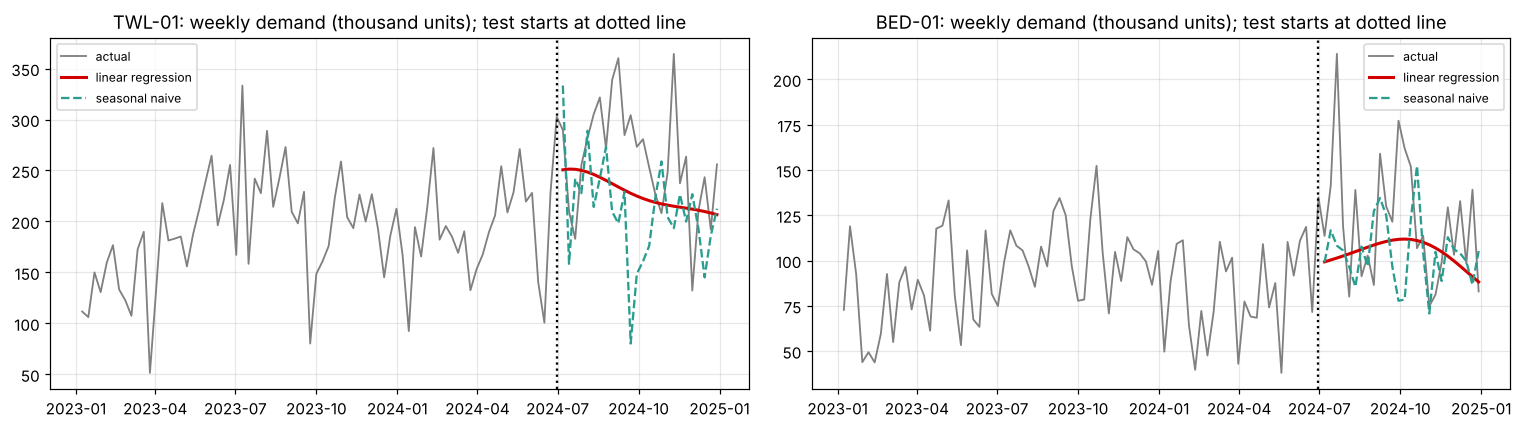

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, sku in zip(ax, ["TWL-01", "BED-01"]):
    y, pr = weekly[sku], preds[sku]
    a.plot(y.index, y / 1e3, color="grey", lw=1.2, label="actual")
    a.plot(pr.index, pr["Linear regression"] / 1e3, color="#d00000", lw=2, label="linear regression")
    a.plot(pr.index, pr["Seasonal naive"] / 1e3, color="#2a9d8f", ls="--", label="seasonal naive")
    a.axvline(SPLIT, color="black", ls=":")
    a.set_title(f"{sku}: weekly demand (thousand units); test starts at dotted line"); a.legend(fontsize=8)
plt.tight_layout()

### Forecast for the next 13 weeks (Q1 2025)

In [11]:
future = pd.date_range(weekly.index[-1] + pd.Timedelta(weeks=1), periods=13, freq="W-SUN")
last_year = weekly.reindex(future - pd.Timedelta(weeks=52))           # same 13 weeks one year earlier

forecast = {}
for sku in weekly.columns:
    model = LinearRegression().fit(make_features(weekly.index), weekly[sku])       # refit on all data
    forecast[sku] = pd.Series(model.predict(make_features(future)), index=future).clip(lower=0)
forecast = pd.DataFrame(forecast)
final = (forecast + last_year.values) / 2          # average of regression and seasonal naive

q1 = pd.DataFrame({"forecast_13w": final.sum(), "same_13w_last_year": last_year.sum().values}).round(0)
q1["change_%"] = (q1.forecast_13w / q1.same_13w_last_year - 1) * 100
q1

,forecast_13w,same_13w_last_year,change_%
BED-01,"1,100,246","1,002,600",9.74
BED-02,"387,742","351,500",10.31
TWL-01,"2,606,345","2,313,000",12.68
TWL-02,"1,555,656","1,403,100",10.87
YRN-01,"1,144,996","1,034,900",10.64


**Takeaway:** demand for the next 13 weeks is forecast at **about 10-13% above the same weeks last year** for every product (for example TWL-01: 2.61M units vs 2.31M).

---

## 7. Summary

| # | Finding | Action |
|---|---|---|
| 1 | OTIF is 69.3%; sea OTIF falls to 51.1% in Aug-Oct | Plan earlier for the peak, pre-book freight, promise realistic dates |
| 2 | Weak suppliers hold 59.6% of cotton spend; imports cost 31% more and take 5x longer | Shift volume to reliable suppliers, order imports earlier |
| 3 | 3 products stocked out (about US$4.35M revenue at risk) while 2 are over-stocked | Reset safety stock per product |
| 4 | Linear-regression forecast averaged with seasonal naive gives 15.1% monthly error | Use it for monthly production planning |

### Limitations
- The data is **synthetic**, so numbers are illustrative; re-run on real data before drawing conclusions.
- No freight cost or currency effects are modelled (cotton prices are in INR, sales in USD).
- Stock-outs are treated as lost sales at list price (some may have been back-ordered).
- Safety stock ignores lead-time variability to keep the formula simple.